In [1]:
import pymc as pm
import pytensor.tensor as pt
from models.melodic_markov_model import MelodicMarkovModel
from models.mm_mode_independent_model import MarkovModeIndependentModel
import data.GradualePipeline as gs

In [2]:
def prepare_sequence_data(initial_states_obs, sequence_states_obs, sequence_lengths_obs):
    initial_states_padded = pt.shape_padleft(initial_states_obs)
    all_states = pt.concatenate([initial_states_padded, sequence_states_obs], axis=0)
    
    prev_states = all_states[:-1]
    current_states = all_states[1:]

    time_indices = pt.arange(sequence_states_obs.shape[0])
    valid_time_mask = time_indices[:, None] < sequence_lengths_obs[None, :]
    
    valid_prev_states = prev_states[valid_time_mask]
    valid_current_states = current_states[valid_time_mask]
    
    return prev_states, current_states, valid_prev_states, valid_current_states, valid_time_mask

In [3]:
def supermodel(initial_states_obs, sequence_states_obs, sequence_lengths_obs, mode_obs):
    m_base = MelodicMarkovModel()
    m_mode = MarkovModeIndependentModel()
    
    with pm.Model() as supermodel:
        model_indicator = pm.Bernoulli("model_indicator", p=0.5)
        with pm.Model(name="base"):
            base_init_probs, base_transition = m_base._define_priors()

        with pm.Model(name="mode"):
            mode_probs, mode_transition, mode_init_probs = m_mode._define_priors()

        prev, curr, valid_prev, valid_curr, valid_mask = prepare_sequence_data(
            initial_states_obs, 
            sequence_states_obs, 
            sequence_lengths_obs
        )

        init_logp_base = pm.logp(pm.Categorical.dist(p=base_init_probs), initial_states_obs)
        step_logp_base = pm.logp(pm.Categorical.dist(p=base_transition[valid_prev]), valid_curr)
        ll_base = pt.sum(init_logp_base) + pt.sum(step_logp_base)

        init_logp_mode = pm.logp(pm.Categorical.dist(p=mode_init_probs), initial_states_obs)
        obs_mode_logp = pm.logp(pm.Categorical.dist(p=mode_probs), mode_obs)
        seq_ll_mode = m_mode._calculate_sequence_logp(
            prev, 
            curr, 
            valid_mask, 
            mode_transition, 
            mode_obs
        )
        ll_mode = pt.sum(init_logp_mode) + pt.sum(obs_mode_logp) + seq_ll_mode

        active_log_likelihood = pm.math.switch(pt.eq(model_indicator, 0), ll_base, ll_mode)
        
        pm.Potential("supermodel_likelihood", active_log_likelihood)
        
    return supermodel

In [4]:
data = gs.GradualePipeline.load("data/processed/dataset_pitches_modes.pkl")
data

{'x_0_obs': array([ 6,  7,  7,  2,  6,  3,  7,  5,  6,  3,  5,  5,  5,  3,  5,  3,  3,
         4,  6,  3,  3,  6,  5,  6,  7,  5,  4,  2,  6,  5,  5,  3,  3,  6,
         9,  5,  5,  7,  6,  7,  3,  3,  6,  6,  5,  9,  3,  7,  9,  3,  3,
         5,  3,  6,  8,  6,  8,  6, 10,  6,  5,  3,  9,  6,  9,  8,  6,  5,
         3,  4,  3,  9,  9,  3,  7,  2,  9,  3,  3,  2,  6,  2,  3,  2,  3,
         6,  3,  3,  3,  7,  6,  5,  6,  5,  3,  7,  5,  7,  6,  6,  5,  9,
         6,  3,  5,  3,  7,  5,  7,  7,  3,  4,  5,  9,  9,  3,  3,  4,  9,
         6,  3,  7,  5,  6,  3,  5,  7,  5,  7,  9,  3,  6,  3,  3]),
 'x_t_obs': array([[ 6,  7,  6, ...,  6,  5,  5],
        [ 7,  7,  5, ...,  5,  5,  3],
        [ 8,  6,  6, ...,  5,  6,  3],
        ...,
        [-1, -1, -1, ..., -1, -1, -1],
        [-1, -1, -1, ..., -1, -1, -1],
        [-1, -1, -1, ..., -1, -1, -1]], shape=(428, 134)),
 'lengths_obs': array([385, 201, 104,  80, 222, 211, 140, 158, 219, 279, 260,  98, 145,
        103, 109, 154

In [5]:
supermodel_obj = supermodel(data["x_0_obs"], data["x_t_obs"], data["lengths_obs"], data["m_obs"])

In [6]:
with supermodel_obj:
    supermodel_trace = pm.sample(draws=2000, tune=1000, chains=4, target_accept=0.9)

Multiprocess sampling (4 chains in 4 jobs)
CompoundStep
>BinaryGibbsMetropolis: [model_indicator]
>NUTS: [base::init_probs, base::transition_matrix, mode::mode_probs, mode::mode_transition_matrices, mode::init_probs]


Output()

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 1762 seconds.
/Users/timeipert/PycharmProjects/generative_medieval_music_model/venvnew/lib/python3.11/site-packages/arviz/stats/diagnostics.py:595: RuntimeWarning: invalid value encountered in sqrt
  rhat_value = np.sqrt(
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


In [7]:
supermodel_trace

Inference data with groups:
	> posterior
	> sample_stats

In [10]:
import arviz as az

array([[<Axes: title={'center': 'model_indicator'}>,
        <Axes: title={'center': 'model_indicator'}>],
       [<Axes: title={'center': 'base::init_probs'}>,
        <Axes: title={'center': 'base::init_probs'}>],
       [<Axes: title={'center': 'base::transition_matrix'}>,
        <Axes: title={'center': 'base::transition_matrix'}>],
       [<Axes: title={'center': 'mode::mode_probs'}>,
        <Axes: title={'center': 'mode::mode_probs'}>],
       [<Axes: title={'center': 'mode::mode_transition_matrices'}>,
        <Axes: title={'center': 'mode::mode_transition_matrices'}>],
       [<Axes: title={'center': 'mode::init_probs'}>,
        <Axes: title={'center': 'mode::init_probs'}>]], dtype=object)

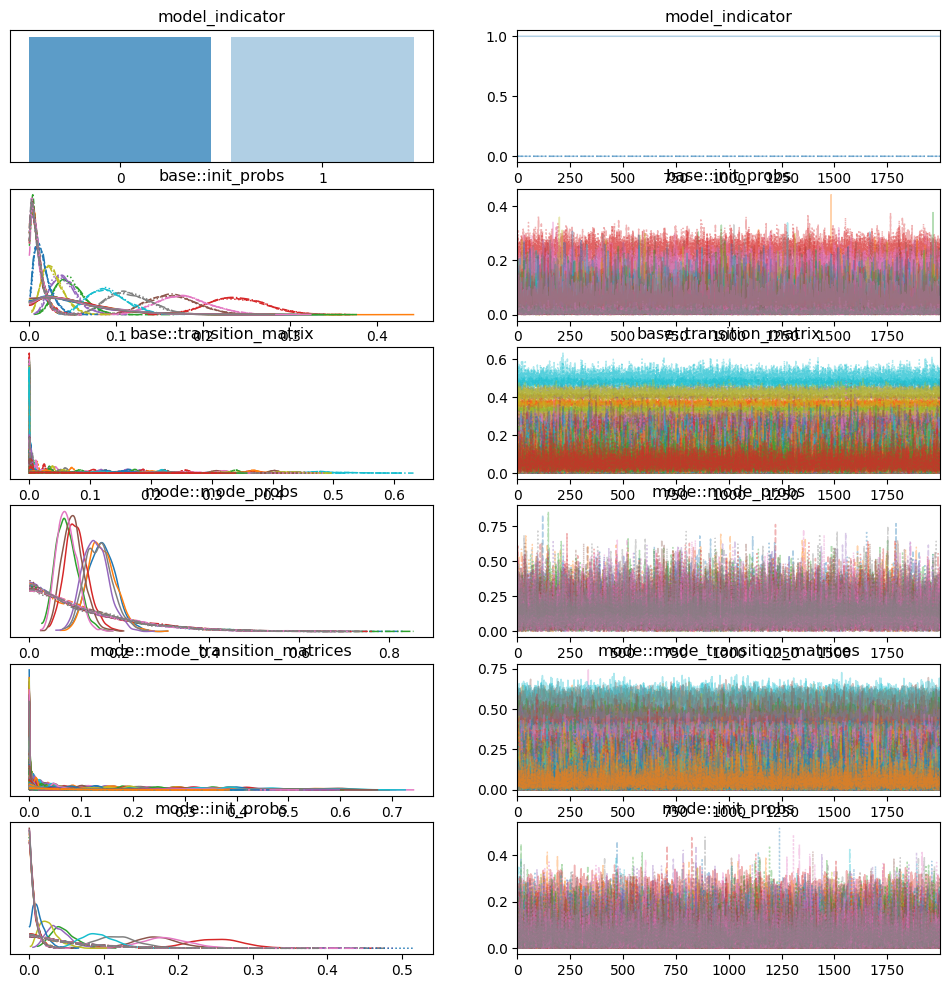

In [12]:
az.plot_trace(supermodel_trace)

In [13]:
supermodel_trace

Inference data with groups:
	> posterior
	> sample_stats

In [14]:
supermodel_trace.mean("draw")

Inference data with groups:
	> posterior
	> sample_stats